In [1]:
import pandas as pd
import random
from datetime import datetime, timedelta

In [2]:
random.seed(42)

regions = ["North", "South", "East", "West", "Central"]

categories = {
    "Electronics": [
        ("Laptop", 55000),
        ("Smartphone", 28000),
        ("Headphones", 2500),
        ("Monitor", 14000)
    ],
    
    "Furniture": [
        ("Office Chair", 8500),
        ("Desk", 12000),
        ("Bookshelf", 6500),
        ("Table Lamp", 1800)
    ],
    
    "Clothing": [
        ("T-Shirt", 800),
        ("Jeans", 1800),
        ("Jacket", 3200),
        ("Shoes", 2800)
    ],
    
    "Office Supplies": [
        ("Notebook", 180),
        ("Printer", 12000),
        ("Pen Set", 250),
        ("Stapler", 350)
    ],
    
    "Home Appliances": [
        ("Mixer", 4200),
        ("Microwave", 11000),
        ("Air Cooler", 8500),
        ("Vacuum Cleaner", 9500)
    ]
}

payment_modes = [
    "UPI",
    "Credit Card",
    "Debit Card",
    "Cash",
    "Net Banking"
]

In [3]:
rows = []

start_date = datetime(2025, 1, 1)

for i in range(1, 501):
    
    category = random.choice(list(categories.keys()))
    product, unit_price = random.choice(categories[category])
    
    quantity = random.randint(1, 5)
    
    discount = random.choice([0, 0, 0, 0.05, 0.10, 0.15])
    
    sales = quantity * unit_price * (1 - discount)
    
    order_date = start_date + timedelta(
        days=random.randint(0, 364)
    )
    
    rows.append({
        "Order_ID": f"ORD{i:04d}",
        "Order_Date": order_date.strftime("%Y-%m-%d"),
        "Customer_Name": f"Customer_{random.randint(1, 150)}",
        "Region": random.choice(regions),
        "Category": category,
        "Product": product,
        "Quantity": quantity,
        "Unit_Price": unit_price,
        "Discount": discount,
        "Sales": round(sales, 2),
        "Payment_Mode": random.choice(payment_modes)
    })

df = pd.DataFrame(rows)

In [4]:
df.head()

,Order_ID,Order_Date,Customer_Name,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Payment_Mode
0,ORD0001,2025-04-25,Customer_36,North,Electronics,Laptop,3,55000,0.0,165000.0,Net Banking
1,ORD0002,2025-02-17,Customer_56,South,Electronics,Monitor,1,14000,0.0,14000.0,Net Banking
2,ORD0003,2025-11-29,Customer_140,West,Home Appliances,Mixer,5,4200,0.0,21000.0,Credit Card
3,ORD0004,2025-12-24,Customer_109,East,Office Supplies,Pen Set,1,250,0.0,250.0,Debit Card
4,ORD0005,2025-02-17,Customer_98,North,Furniture,Desk,3,12000,0.0,36000.0,Debit Card


In [5]:
df.shape

(500, 11)

In [6]:
df.to_csv("../data/sales_data.csv", index=False)

In [7]:
df.head
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       500 non-null    str    
 1   Order_Date     500 non-null    str    
 2   Customer_Name  500 non-null    str    
 3   Region         500 non-null    str    
 4   Category       500 non-null    str    
 5   Product        500 non-null    str    
 6   Quantity       500 non-null    int64  
 7   Unit_Price     500 non-null    int64  
 8   Discount       500 non-null    float64
 9   Sales          500 non-null    float64
 10  Payment_Mode   500 non-null    str    
dtypes: float64(2), int64(2), str(7)
memory usage: 43.1 KB


In [8]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       500 non-null    str           
 1   Order_Date     500 non-null    datetime64[us]
 2   Customer_Name  500 non-null    str           
 3   Region         500 non-null    str           
 4   Category       500 non-null    str           
 5   Product        500 non-null    str           
 6   Quantity       500 non-null    int64         
 7   Unit_Price     500 non-null    int64         
 8   Discount       500 non-null    float64       
 9   Sales          500 non-null    float64       
 10  Payment_Mode   500 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(2), str(6)
memory usage: 43.1 KB


In [10]:
df.describe()

,Order_Date,Quantity,Unit_Price,Discount,Sales
count,500,500.000000,500.000000,500.000000,500.000000
mean,2025-07-09 19:14:52.800000,3.064000,8831.000000,0.050000,25280.396000
min,2025-01-01 00:00:00,1.000000,180.000000,0.000000,162.000000
25%,2025-04-07 00:00:00,2.000000,1800.000000,0.000000,3735.000000
50%,2025-07-16 00:00:00,3.000000,4200.000000,0.000000,11200.000000
75%,2025-10-06 06:00:00,4.000000,11000.000000,0.100000,32325.000000
max,2025-12-31 00:00:00,5.000000,55000.000000,0.150000,275000.000000
std,NaN,1.381202,12157.984132,0.058454,39033.504185


In [11]:
df.to_csv("../data/sales_data.csv", index=False)

In [12]:
df["Sales"].sum()

np.float64(12640198.0)

In [13]:
df["Sales"].mean()

np.float64(25280.396)

In [14]:
region_sales = df.groupby("Region")["Sales"].sum()
region_sales

Region
Central    2423306.5
East       2401763.0
North      2144511.5
South      3032680.0
West       2637937.0
Name: Sales, dtype: float64

In [15]:
region_sales.idxmax()

'South'

In [16]:
region_sales.max()

np.float64(3032680.0)

In [17]:
region_sales.sort_values(ascending=False)

Region
South      3032680.0
West       2637937.0
Central    2423306.5
East       2401763.0
North      2144511.5
Name: Sales, dtype: float64

In [18]:
category_sales = df.groupby("Category")["Sales"].sum()
category_sales

Category
Clothing            701190.0
Electronics        6784600.0
Furniture          1932780.0
Home Appliances    2491130.0
Office Supplies     730498.0
Name: Sales, dtype: float64

In [19]:
category_sales.idxmax()

'Electronics'

In [20]:
product_sales = df.groupby("Product")["Sales"].sum()
product_sales

Product
Air Cooler         649825.0
Bookshelf          395525.0
Desk               783600.0
Headphones         242500.0
Jacket             211840.0
Jeans              155610.0
Laptop            3470500.0
Microwave          851400.0
Mixer              308280.0
Monitor            694400.0
Notebook             8073.0
Office Chair       609025.0
Pen Set             14775.0
Printer            678600.0
Shoes              262220.0
Smartphone        2377200.0
Stapler             29050.0
T-Shirt             71520.0
Table Lamp         144630.0
Vacuum Cleaner     681625.0
Name: Sales, dtype: float64

In [21]:
product_sales.sort_values(ascending=False)

Product
Laptop            3470500.0
Smartphone        2377200.0
Microwave          851400.0
Desk               783600.0
Monitor            694400.0
Vacuum Cleaner     681625.0
Printer            678600.0
Air Cooler         649825.0
Office Chair       609025.0
Bookshelf          395525.0
Mixer              308280.0
Shoes              262220.0
Headphones         242500.0
Jacket             211840.0
Jeans              155610.0
Table Lamp         144630.0
T-Shirt             71520.0
Stapler             29050.0
Pen Set             14775.0
Notebook             8073.0
Name: Sales, dtype: float64

In [22]:
product_sales.idxmax()

'Laptop'

In [23]:
product_sales.idxmin()

'Notebook'

In [24]:
total_quantity = df["Quantity"].sum()
total_quantity

np.int64(1532)

In [25]:
df["Quantity"].mean()

np.float64(3.064)

In [26]:
product_quantity = df.groupby("Product")["Quantity"].sum()
product_quantity.sort_values(ascending=False)

Product
Headphones        101
Shoes              98
T-Shirt            95
Jeans              92
Smartphone         88
Stapler            88
Table Lamp         85
Microwave          80
Air Cooler         79
Mixer              79
Vacuum Cleaner     77
Office Chair       76
Jacket             70
Desk               68
Laptop             67
Bookshelf          64
Pen Set            62
Printer            61
Monitor            54
Notebook           48
Name: Quantity, dtype: int64

In [27]:
product_quantity.idxmax()

'Headphones'

In [28]:
df["Month"] = df["Order_Date"].dt.to_period("M")

In [29]:
monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales

Month
2025-01     905087.5
2025-02    1319880.0
2025-03    1020028.5
2025-04     579341.5
2025-05    1447387.0
2025-06     990035.0
2025-07    1267746.0
2025-08    1318462.5
2025-09     866332.5
2025-10     614162.0
2025-11     920243.0
2025-12    1391492.5
Freq: M, Name: Sales, dtype: float64

In [30]:
monthly_sales.idxmax()

Period('2025-05', 'M')

In [31]:
monthly_sales.idxmin()

Period('2025-04', 'M')

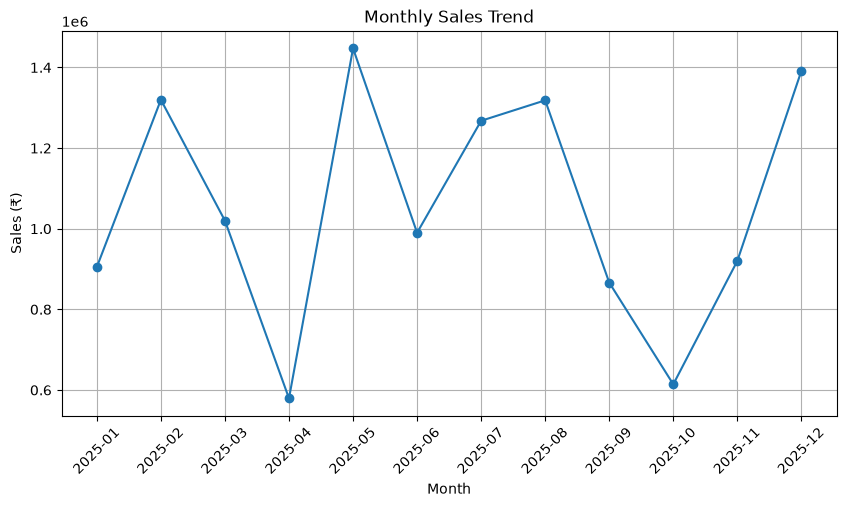

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [33]:
top_5_products = product_sales.sort_values(ascending=False).head(5)
top_5_products

Product
Laptop        3470500.0
Smartphone    2377200.0
Microwave      851400.0
Desk           783600.0
Monitor        694400.0
Name: Sales, dtype: float64

In [34]:
region_avg_order = df.groupby("Region")["Sales"].mean()

region_avg_order.sort_values(ascending=False)

Region
South      29160.384615
Central    26057.059140
North      24369.448864
West       23765.198198
East       23093.875000
Name: Sales, dtype: float64

In [35]:
region_orders = df.groupby("Region")["Order_ID"].count()
region_orders

Region
Central     93
East       104
North       88
South      104
West       111
Name: Order_ID, dtype: int64

In [36]:
region_orders.sort_values(ascending=False)

Region
West       111
South      104
East       104
Central     93
North       88
Name: Order_ID, dtype: int64

In [37]:
avg_quantity_order = df.groupby("Region")["Quantity"].mean()
avg_quantity_order

Region
Central    3.021505
East       3.076923
North      2.875000
South      3.250000
West       3.063063
Name: Quantity, dtype: float64

In [38]:
avg_quantity_order.sort_values(ascending=False)

Region
South      3.250000
East       3.076923
West       3.063063
Central    3.021505
North      2.875000
Name: Quantity, dtype: float64

In [39]:
region_sales.sort_values(ascending=False).head(3)

Region
South      3032680.0
West       2637937.0
Central    2423306.5
Name: Sales, dtype: float64

In [40]:
region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count")
)

region_summary.sort_values("Total_Sales", ascending=False)

,Total_Sales,Total_Orders
Region,,
South,3032680.0,104
West,2637937.0,111
Central,2423306.5,93
East,2401763.0,104
North,2144511.5,88


In [41]:
region_avg_order = df.groupby("Region")["Sales"].mean()

region_avg_order.sort_values(ascending=False)

Region
South      29160.384615
Central    26057.059140
North      24369.448864
West       23765.198198
East       23093.875000
Name: Sales, dtype: float64

In [42]:
product_summary = df.groupby("Product").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
)

product_summary.sort_values("Total_Sales", ascending=False).head(5)

,Total_Sales,Total_Quantity
Product,,
Laptop,3470500.0,67
Smartphone,2377200.0,88
Microwave,851400.0,80
Desk,783600.0,68
Monitor,694400.0,54


In [43]:
product_summary.sort_values("Total_Sales").head(5)

,Total_Sales,Total_Quantity
Product,,
Notebook,8073.0,48
Pen Set,14775.0,62
Stapler,29050.0,88
T-Shirt,71520.0,95
Table Lamp,144630.0,85


In [44]:
df[df["Product"] == "Notebook"]["Unit_Price"].unique()

array([180])

In [45]:
product_summary.sort_values("Total_Quantity", ascending=False).head(5)

,Total_Sales,Total_Quantity
Product,,
Headphones,242500.0,101
Shoes,262220.0,98
T-Shirt,71520.0,95
Jeans,155610.0,92
Smartphone,2377200.0,88


In [46]:
category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
)

category_summary.sort_values("Total_Sales", ascending=False)

,Total_Sales,Total_Quantity
Category,,
Electronics,6784600.0,310
Home Appliances,2491130.0,315
Furniture,1932780.0,293
Office Supplies,730498.0,259
Clothing,701190.0,355


In [47]:
electronics = df[df["Category"] == "Electronics"]

electronics.groupby("Product")["Sales"].sum().sort_values(ascending=False)

Product
Laptop        3470500.0
Smartphone    2377200.0
Monitor        694400.0
Headphones     242500.0
Name: Sales, dtype: float64

In [48]:
electronics.groupby("Product").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unit_Price=("Unit_Price", "mean")
).sort_values("Total_Sales", ascending=False)

,Total_Sales,Total_Quantity,Unit_Price
Product,,,
Laptop,3470500.0,67,55000.0
Smartphone,2377200.0,88,28000.0
Monitor,694400.0,54,14000.0
Headphones,242500.0,101,2500.0


In [49]:
customer_sales = df.groupby("Customer_Name")["Sales"].sum()

customer_sales.sort_values(ascending=False).head(5)

Customer_Name
Customer_61     533225.0
Customer_94     388000.0
Customer_62     322200.0
Customer_73     321245.0
Customer_138    318902.5
Name: Sales, dtype: float64

In [50]:
customer_orders = df.groupby("Customer_Name")["Order_ID"].count()

customer_orders.sort_values(ascending=False).head(5)

Customer_Name
Customer_126    11
Customer_138     9
Customer_102     8
Customer_20      8
Customer_45      8
Name: Order_ID, dtype: int64

In [51]:
customer_summary = df.groupby("Customer_Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count")
)

customer_summary.sort_values("Total_Sales", ascending=False).head(10)

,Total_Sales,Total_Orders
Customer_Name,,
Customer_61,533225.0,5
Customer_94,388000.0,4
Customer_62,322200.0,6
Customer_73,321245.0,4
Customer_138,318902.5,9
Customer_102,302100.0,8
Customer_136,288190.0,3
Customer_140,264830.0,6
Customer_45,239660.0,8


In [52]:
customer_avg_order = df.groupby("Customer_Name")["Sales"].mean()

customer_avg_order.sort_values(ascending=False).head(10)

Customer_Name
Customer_61     106645.000000
Customer_124    104500.000000
Customer_94      97000.000000
Customer_136     96063.333333
Customer_24      95250.000000
Customer_46      84000.000000
Customer_67      83900.000000
Customer_73      80311.250000
Customer_117     78000.000000
Customer_125     71800.000000
Name: Sales, dtype: float64

In [53]:
customer_61 = df[df["Customer_Name"] == "Customer_61"]

customer_61[["Order_ID", "Product", "Category", "Quantity", "Unit_Price", "Discount", "Sales"]]

,Order_ID,Product,Category,Quantity,Unit_Price,Discount,Sales
31,ORD0032,Laptop,Electronics,5,55000,0.00,275000.0
49,ORD0050,Vacuum Cleaner,Home Appliances,5,9500,0.15,40375.0
430,ORD0431,Pen Set,Office Supplies,1,250,0.00,250.0
433,ORD0434,Laptop,Electronics,4,55000,0.15,187000.0
463,ORD0464,Printer,Office Supplies,3,12000,0.15,30600.0


In [54]:
customer_138 = df[df["Customer_Name"] == "Customer_138"]

customer_138[["Order_ID", "Product", "Category", "Quantity", "Unit_Price", "Discount", "Sales"]]

,Order_ID,Product,Category,Quantity,Unit_Price,Discount,Sales
5,ORD0006,Jacket,Clothing,1,3200,0.15,2720.0
12,ORD0013,Jeans,Clothing,2,1800,0.15,3060.0
29,ORD0030,T-Shirt,Clothing,2,800,0.00,1600.0
74,ORD0075,Headphones,Electronics,3,2500,0.05,7125.0
96,ORD0097,Office Chair,Furniture,2,8500,0.00,17000.0
330,ORD0331,Laptop,Electronics,5,55000,0.15,233750.0
360,ORD0361,Vacuum Cleaner,Home Appliances,5,9500,0.00,47500.0
371,ORD0372,Bookshelf,Furniture,1,6500,0.10,5850.0
412,ORD0413,Stapler,Office Supplies,1,350,0.15,297.5


In [55]:
discount_sales = df.groupby("Discount")["Sales"].sum()

discount_sales

Discount
0.00    6563690.0
0.05    2101571.0
0.10    1867005.0
0.15    2107932.0
Name: Sales, dtype: float64

In [56]:
discount_orders = df.groupby("Discount")["Order_ID"].count()

discount_orders

Discount
0.00    252
0.05     85
0.10     74
0.15     89
Name: Order_ID, dtype: int64

In [57]:
discount_avg_sales = df.groupby("Discount")["Sales"].mean()

discount_avg_sales

Discount
0.00    26046.388889
0.05    24724.364706
0.10    25229.797297
0.15    23684.629213
Name: Sales, dtype: float64

In [58]:
discount_avg_quantity = df.groupby("Discount")["Quantity"].mean()

discount_avg_quantity

Discount
0.00    2.928571
0.05    3.070588
0.10    3.229730
0.15    3.303371
Name: Quantity, dtype: float64

In [59]:
discount_summary = df.groupby("Discount").agg(
    Avg_Quantity=("Quantity", "mean"),
    Avg_Sales=("Sales", "mean")
)

discount_summary

,Avg_Quantity,Avg_Sales
Discount,,
0.00,2.928571,26046.388889
0.05,3.070588,24724.364706
0.10,3.229730,25229.797297
0.15,3.303371,23684.629213


In [60]:
discount_product = df.groupby(["Discount", "Product"])["Sales"].sum()
discount_product

Discount  Product       
0.00      Air Cooler        433500.0
          Bookshelf         169000.0
          Desk              432000.0
          Headphones        140000.0
          Jacket            112000.0
                              ...   
0.15      Smartphone        142800.0
          Stapler             3272.5
          T-Shirt            15640.0
          Table Lamp         24480.0
          Vacuum Cleaner    193800.0
Name: Sales, Length: 80, dtype: float64

In [61]:
product_discount = df.groupby("Product")["Discount"].mean()
product_discount.sort_values(ascending=False)

Product
Jeans             0.069355
Mixer             0.068750
Printer           0.067647
Monitor           0.065000
Notebook          0.065000
Stapler           0.062000
Vacuum Cleaner    0.060000
Laptop            0.058696
Pen Set           0.050000
Bookshelf         0.050000
Jacket            0.047826
Office Chair      0.046000
Table Lamp        0.044444
Shoes             0.043333
T-Shirt           0.040625
Headphones        0.039286
Desk              0.039130
Air Cooler        0.036538
Smartphone        0.032143
Microwave         0.031481
Name: Discount, dtype: float64

In [62]:
discount_summary.sort_values("Discount")

,Avg_Quantity,Avg_Sales
Discount,,
0.00,2.928571,26046.388889
0.05,3.070588,24724.364706
0.10,3.229730,25229.797297
0.15,3.303371,23684.629213


In [63]:
df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count"),
    Avg_Sales=("Sales", "mean"),
    Avg_Quantity=("Quantity", "mean")
)

,Total_Sales,Total_Orders,Avg_Sales,Avg_Quantity
Discount,,,,
0.00,6563690.0,252,26046.388889,2.928571
0.05,2101571.0,85,24724.364706,3.070588
0.10,1867005.0,74,25229.797297,3.229730
0.15,2107932.0,89,23684.629213,3.303371


In [64]:
payment_sales = df.groupby("Payment_Mode")["Sales"].sum()

payment_sales.sort_values(ascending=False)

Payment_Mode
UPI            3015491.5
Cash           2794024.5
Net Banking    2793252.0
Credit Card    2163369.0
Debit Card     1874061.0
Name: Sales, dtype: float64

In [65]:
payment_orders = df.groupby("Payment_Mode")["Order_ID"].count()

payment_orders.sort_values(ascending=False)

Payment_Mode
Cash           110
UPI            104
Credit Card     99
Net Banking     98
Debit Card      89
Name: Order_ID, dtype: int64

In [66]:
payment_avg_sales = df.groupby("Payment_Mode")["Sales"].mean()

payment_avg_sales.sort_values(ascending=False)

Payment_Mode
UPI            28995.110577
Net Banking    28502.571429
Cash           25400.222727
Credit Card    21852.212121
Debit Card     21056.865169
Name: Sales, dtype: float64

In [67]:
payment_avg_quantity = df.groupby("Payment_Mode")["Quantity"].mean()

payment_avg_quantity.sort_values(ascending=False)

Payment_Mode
Debit Card     3.325843
Cash           3.063636
Credit Card    3.020202
Net Banking    3.010204
UPI            2.932692
Name: Quantity, dtype: float64

In [68]:
payment_avg_price = df.groupby("Payment_Mode")["Unit_Price"].mean()

payment_avg_price.sort_values(ascending=False)

Payment_Mode
Net Banking    10376.020408
UPI             9452.403846
Credit Card     8866.060606
Cash            8593.181818
Debit Card      6658.539326
Name: Unit_Price, dtype: float64

In [69]:
payment_avg_discount = df.groupby("Payment_Mode")["Discount"].mean()

payment_avg_discount.sort_values(ascending=False)

Payment_Mode
Credit Card    0.058081
Debit Card     0.052247
UPI            0.049519
Cash           0.045909
Net Banking    0.044898
Name: Discount, dtype: float64

In [70]:
category_region_sales = df.groupby(["Region", "Category"])["Sales"].sum()

category_region_sales

Region   Category       
Central  Clothing            123360.0
         Electronics        1352200.0
         Furniture           339870.0
         Home Appliances     421625.0
         Office Supplies     186251.5
East     Clothing            166800.0
         Electronics        1322200.0
         Furniture           378365.0
         Home Appliances     421430.0
         Office Supplies     112968.0
North    Clothing             47300.0
         Electronics        1105700.0
         Furniture           260160.0
         Home Appliances     521185.0
         Office Supplies     210166.5
South    Clothing            173250.0
         Electronics        1752500.0
         Furniture           455625.0
         Home Appliances     547455.0
         Office Supplies     103850.0
West     Clothing            190480.0
         Electronics        1252000.0
         Furniture           498760.0
         Home Appliances     579435.0
         Office Supplies     117262.0
Name: Sales, dtype: float

In [71]:
category_avg_sales = df.groupby("Category")["Sales"].mean()

category_avg_sales.sort_values(ascending=False)

Category
Electronics        68531.313131
Home Appliances    24422.843137
Furniture          19327.800000
Office Supplies     8801.180723
Clothing            6044.741379
Name: Sales, dtype: float64

In [72]:
df[["Quantity", "Unit_Price", "Discount", "Sales"]].corr()

,Quantity,Unit_Price,Discount,Sales
Quantity,1.000000,-0.023731,0.110456,0.264616
Unit_Price,-0.023731,1.000000,-0.011282,0.870401
Discount,0.110456,-0.011282,1.000000,-0.021116
Sales,0.264616,0.870401,-0.021116,1.000000


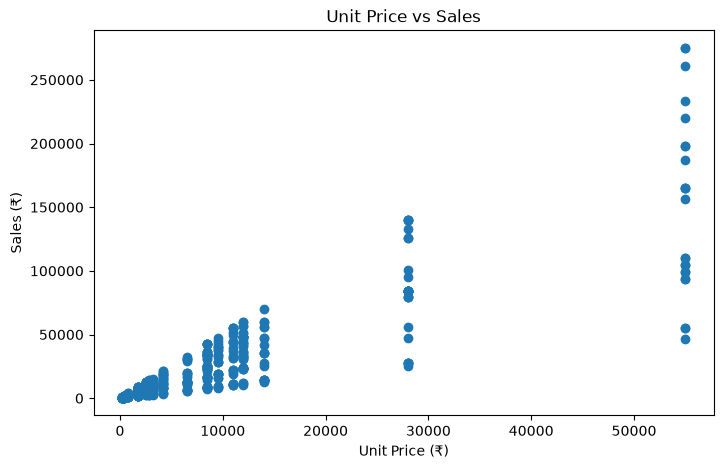

In [73]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Unit_Price"], df["Sales"])

plt.title("Unit Price vs Sales")
plt.xlabel("Unit Price (₹)")
plt.ylabel("Sales (₹)")

plt.show()

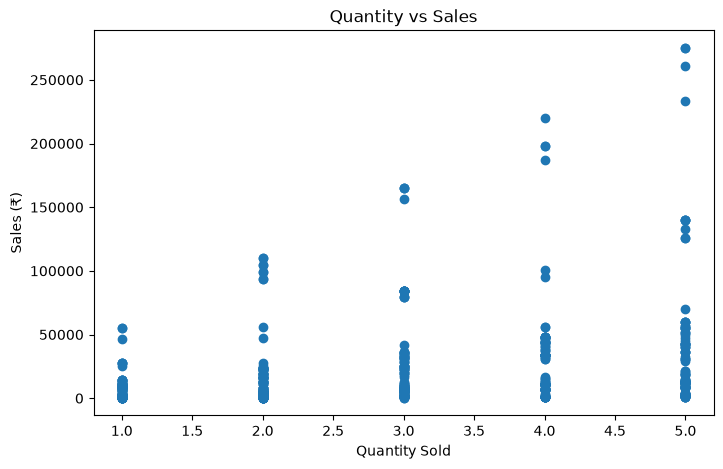

In [74]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Quantity"], df["Sales"])

plt.title("Quantity vs Sales")
plt.xlabel("Quantity Sold")
plt.ylabel("Sales (₹)")

plt.show()

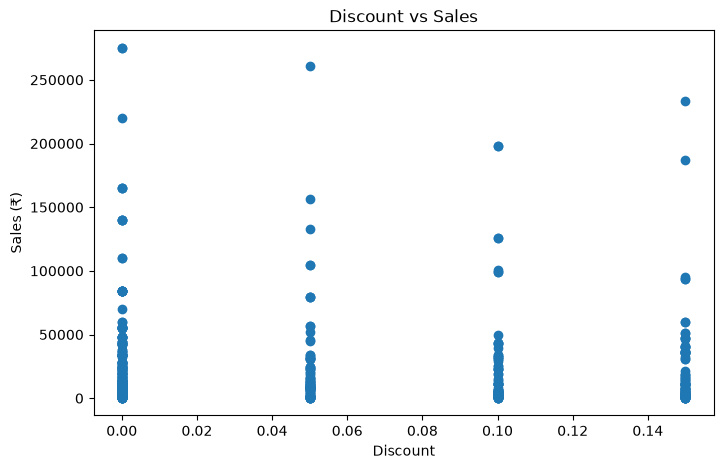

In [75]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Discount"], df["Sales"])

plt.title("Discount vs Sales")
plt.xlabel("Discount")
plt.ylabel("Sales (₹)")

plt.show()

In [76]:
df.isnull().sum()

Order_ID         0
Order_Date       0
Customer_Name    0
Region           0
Category         0
Product          0
Quantity         0
Unit_Price       0
Discount         0
Sales            0
Payment_Mode     0
Month            0
dtype: int64

In [77]:
df["Order_ID"].duplicated().sum()

np.int64(0)

In [78]:
df.dtypes

Order_ID                    str
Order_Date       datetime64[us]
Customer_Name               str
Region                      str
Category                    str
Product                     str
Quantity                  int64
Unit_Price                int64
Discount                float64
Sales                   float64
Payment_Mode                str
Month                 period[M]
dtype: object

In [79]:
expected_sales = (
    df["Quantity"]
    * df["Unit_Price"]
    * (1 - df["Discount"])
)

(df["Sales"] - expected_sales).abs().max()

np.float64(0.0)

In [80]:
df.to_csv("../data/sales_data.csv", index=False)

print("Dataset saved successfully!")
print("Dataset shape:", df.shape)

Dataset saved successfully!
Dataset shape: (500, 12)


In [82]:
df['Payment_Mode'].value_counts()

Payment_Mode
Cash           110
UPI            104
Credit Card     99
Net Banking     98
Debit Card      89
Name: count, dtype: int64

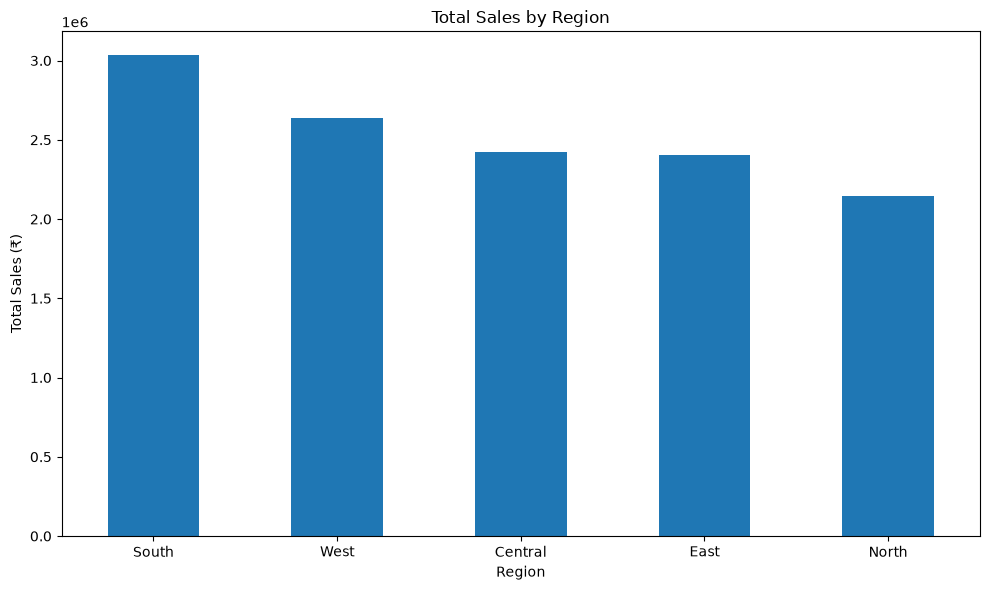

In [83]:
import matplotlib.pyplot as plt

# Calculate total sales for each region
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 6))
region_sales.plot(kind='bar')

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=0)
plt.tight_layout()

# Save the chart
plt.savefig('../Dashboard/sales_by_region.png', dpi=300, bbox_inches='tight')

plt.show()


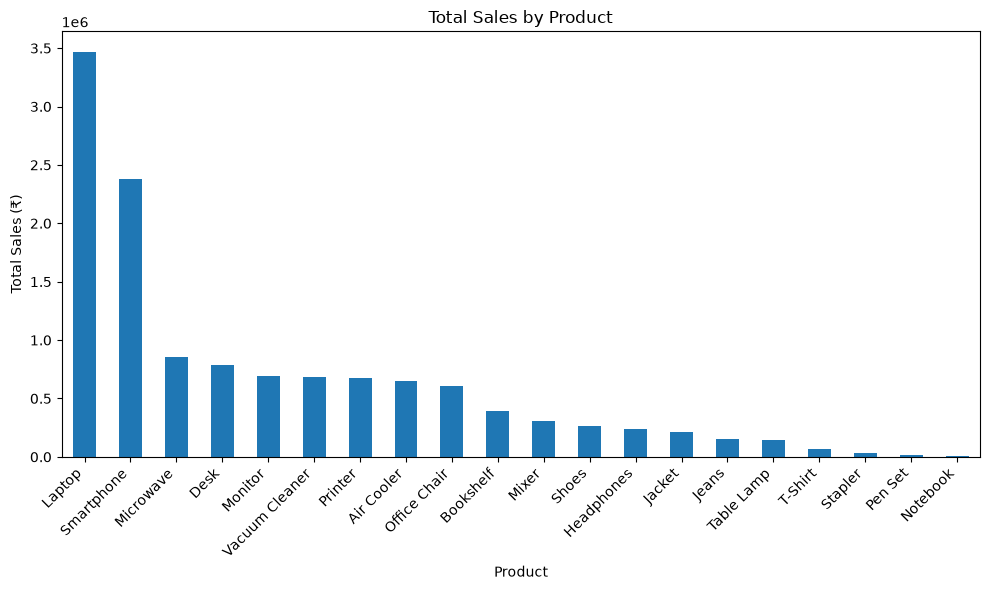

In [84]:
# Calculate total sales for each product
product_sales = df.groupby('Product')['Sales'].sum().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 6))
product_sales.plot(kind='bar')

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save the chart
plt.savefig('../Dashboard/sales_by_product.png', dpi=300, bbox_inches='tight')

plt.show()

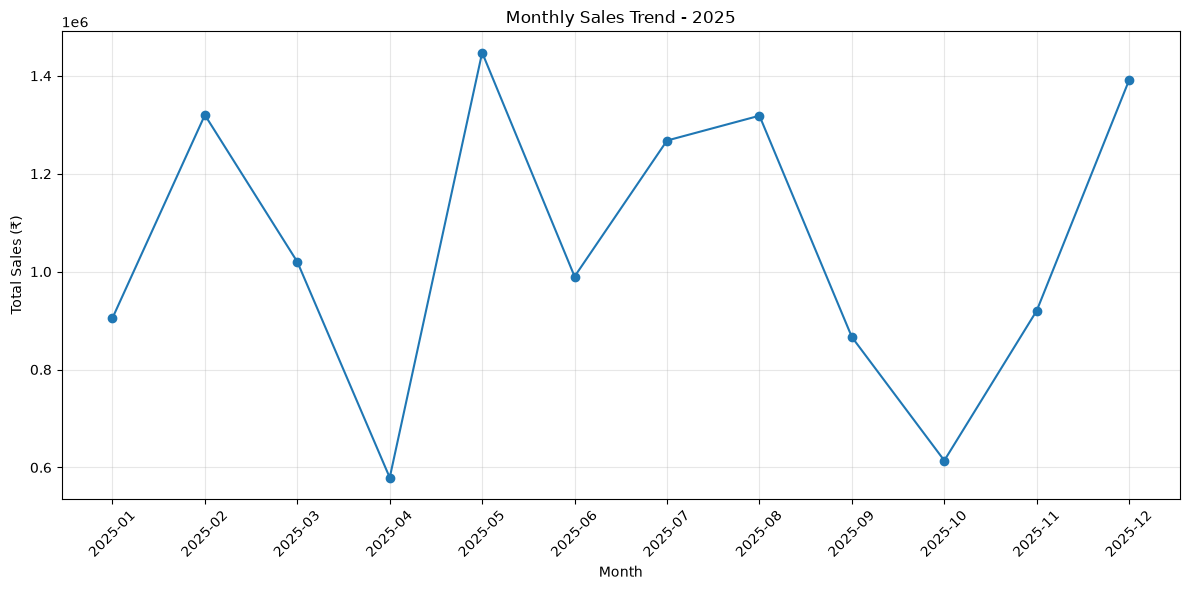

In [88]:
# Calculate total sales for each month
monthly_sales = df.groupby('Month')['Sales'].sum().sort_index()

# Create the line chart
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend - 2025')
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig('../Dashboard/monthly_sales_trend.png',
            dpi=300, bbox_inches='tight')

plt.show()

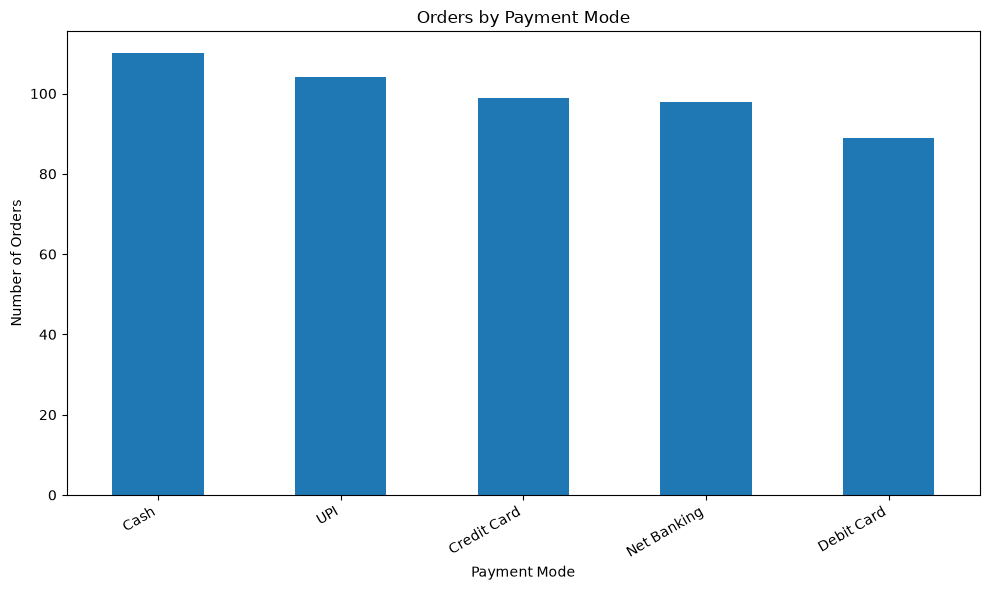

In [90]:
# Count orders for each payment mode
payment_counts = df['Payment_Mode'].value_counts()

# Create the bar chart
plt.figure(figsize=(10, 6))
payment_counts.plot(kind='bar')

plt.title('Orders by Payment Mode')
plt.xlabel('Payment Mode')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Save the chart
plt.savefig('../Dashboard/payment_mode_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()